# Computing attenuation probabilities per country

**Attenution probability =** local probability of a direct warehouse hit in the country.

**Source:** [Wikipedia](https://en.wikipedia.org/wiki/List_of_European_countries_by_area)

We scale attenuation probability by area, and logarithmically:

$$
\alpha = \alpha_{\text{max}} - \frac{\text{ln}(A) - \text{ln}(A_{\text{min}})}{\text{ln}(A_{\text{max}}) - \text{ln}(A_{\text{min}})} \times (\alpha_{\text{max}} - \alpha_{\text{min}})
$$

Where:
- $\alpha$ the computed attenuation probability for a specific country
- $A$ is the area of the country in square kilometers
- $A_{\text{min}}$ and $A_{\text{max}}$ the minimum/maximum country areas across the dataset

Similarly as in Klibi's paper (2012): $\alpha_{\text{min}} = 0.1$ and $\alpha_{\text{max}} = 0.5$.

In [68]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [59]:
df_risks = pd.read_csv("../Data/Results/CLEAN_disasters_europe.csv")
df_risks["Country"].unique()

<StringArray>
[        'United Kingdom',                 'Norway',                 'France',
                'Austria',             'Luxembourg',                 'Sweden',
            'Netherlands',                'Germany',            'Switzerland',
                'Ireland',                'Denmark',                'Finland',
                'Belgium',          'Liechtenstein',                  'Spain',
                 'Russia',                 'Latvia', 'Bosnia and Herzegovina',
                 'Greece',                 'Poland',                'Belarus',
                'Hungary',               'Bulgaria',                'Albania',
                'Romania',                  'Italy',                 'Serbia',
                'Moldova',                'Ukraine',                'Croatia',
                'Iceland',               'Portugal',               'Slovakia',
               'Slovenia',                'Czechia',                'Estonia',
                  'Malta',            

In [58]:
AREAS = {'United Kingdom' : 244381,                 
        'Norway' : 385207,                 
        'France' : 543941,
        'Austria': 83878,             
        'Luxembourg': 2586,                 
        'Sweden' : 438574,
        'Netherlands': 41543,                
        'Germany': 357581,            
        'Switzerland': 41291,
        'Ireland': 69825,                
        'Denmark': 42947,                
        'Finland' : 336884,
        'Belgium' : 30528,          
        'Liechtenstein' : 160,                  
        'Spain' : 498485,
        'Russia' : 3952550,                 
        'Latvia' : 64594, 
        'Bosnia and Herzegovina' : 51209,
        'Greece' : 131957,                 
        'Poland' : 312679,                
        'Belarus' : 207600,
        'Hungary' : 93025,               
        'Bulgaria' : 110994,                
        'Albania' : 28748,
        'Romania' : 238298,                  
        'Italy' : 301958,                 
        'Serbia' : 77589,
        'Moldova' : 33847,                
        'Ukraine' : 603549,                
        'Croatia' : 56594,
        'Iceland' : 103000,              
        'Slovakia' : 49035,
        'Slovenia' : 20273,                
        'Czechia' : 78871,                
        'Estonia' : 45399,
        'Portugal' : 91424,                  
        'Malta' : 315,             
        'Montenegro' : 13888,
        'North Macedonia' : 25713,             
        'Lithuania' : 65286
}

In [63]:
df_attenuation = pd.DataFrame(
    list(AREAS.items()), columns = ["Country", "Area_km2"]
)

log_A_MIN = np.log(df_attenuation["Area_km2"].min())
log_A_MAX = np.log(df_attenuation["Area_km2"].max())

ALPHA_MIN = 0.1
ALPHA_MAX = 0.5

df_attenuation["alpha"] = ALPHA_MAX - ((np.log(df_attenuation["Area_km2"]) - log_A_MIN) / (log_A_MAX - log_A_MIN)) * (ALPHA_MAX - ALPHA_MIN)
df_attenuation = df_attenuation.sort_values(by = "Area_km2", ascending = False).reset_index(drop = True)

pd.set_option("display.max_rows", None)
df_attenuation

                   Country  Area_km2     alpha
0                   Russia   3952550  0.100000
1                  Ukraine    603549  0.174319
2                   France    543941  0.178431
3                    Spain    498485  0.181883
4                   Sweden    438574  0.186946
5                   Norway    385207  0.192077
6                  Germany    357581  0.195020
7                  Finland    336884  0.197378
8                   Poland    312679  0.200327
9                    Italy    301958  0.201707
10          United Kingdom    244381  0.210073
11                 Romania    238298  0.211070
12                 Belarus    207600  0.216524
13                  Greece    131957  0.234444
14                Bulgaria    110994  0.241285
15                 Iceland    103000  0.244241
16                 Hungary     93025  0.248269
17                Portugal     91424  0.248956
18                 Austria     83878  0.252363
19                 Czechia     78871  0.254797
20           

,Country,Area_km2,alpha
0,Russia,3952550,0.100000
1,Ukraine,603549,0.174319
2,France,543941,0.178431
3,Spain,498485,0.181883
4,Sweden,438574,0.186946
5,Norway,385207,0.192077
6,Germany,357581,0.195020
7,Finland,336884,0.197378
8,Poland,312679,0.200327
9,Italy,301958,0.201707


In [64]:
output_csv_path = "../Data/Results/attenuation_probas.csv"
export_cols = [
    "Country",
    "Area_km2",
    "alpha"
]
df_attenuation[export_cols].to_csv(output_csv_path, index=False)


In [75]:
ISO3_MAP = {
    'Russia': 'RUS',
    'Ukraine': 'UKR',
    'France': 'FRA',
    'Spain': 'ESP',
    'Sweden': 'SWE',
    'Norway': 'NOR',
    'Germany': 'DEU',
    'Finland': 'FIN',
    'Poland': 'POL',
    'Italy': 'ITA',
    'United Kingdom': 'GBR',
    'Romania': 'ROU',
    'Belarus': 'BLR',
    'Greece': 'GRC',
    'Bulgaria': 'BGR',
    'Iceland': 'ISL',
    'Hungary': 'HUN',
    'Portugal': 'PRT',
    'Austria': 'AUT',
    'Czechia': 'CZE',
    'Serbia': 'SRB',
    'Ireland': 'IRL',
    'Lithuania': 'LTU',
    'Latvia': 'LVA',
    'Croatia': 'HRV',
    'Bosnia and Herzegovina': 'BIH',
    'Slovakia': 'SVK',
    'Estonia': 'EST',
    'Denmark': 'DNK',
    'Netherlands': 'NLD',
    'Switzerland': 'CHE',
    'Moldova': 'MDA',
    'Belgium': 'BEL',
    'Albania': 'ALB',
    'North Macedonia': 'MKD',
    'Slovenia': 'SVN',
    'Montenegro': 'MNE',
    'Luxembourg': 'LUX',
    'Malta': 'MLT',
    'Liechtenstein': 'LIE',
}

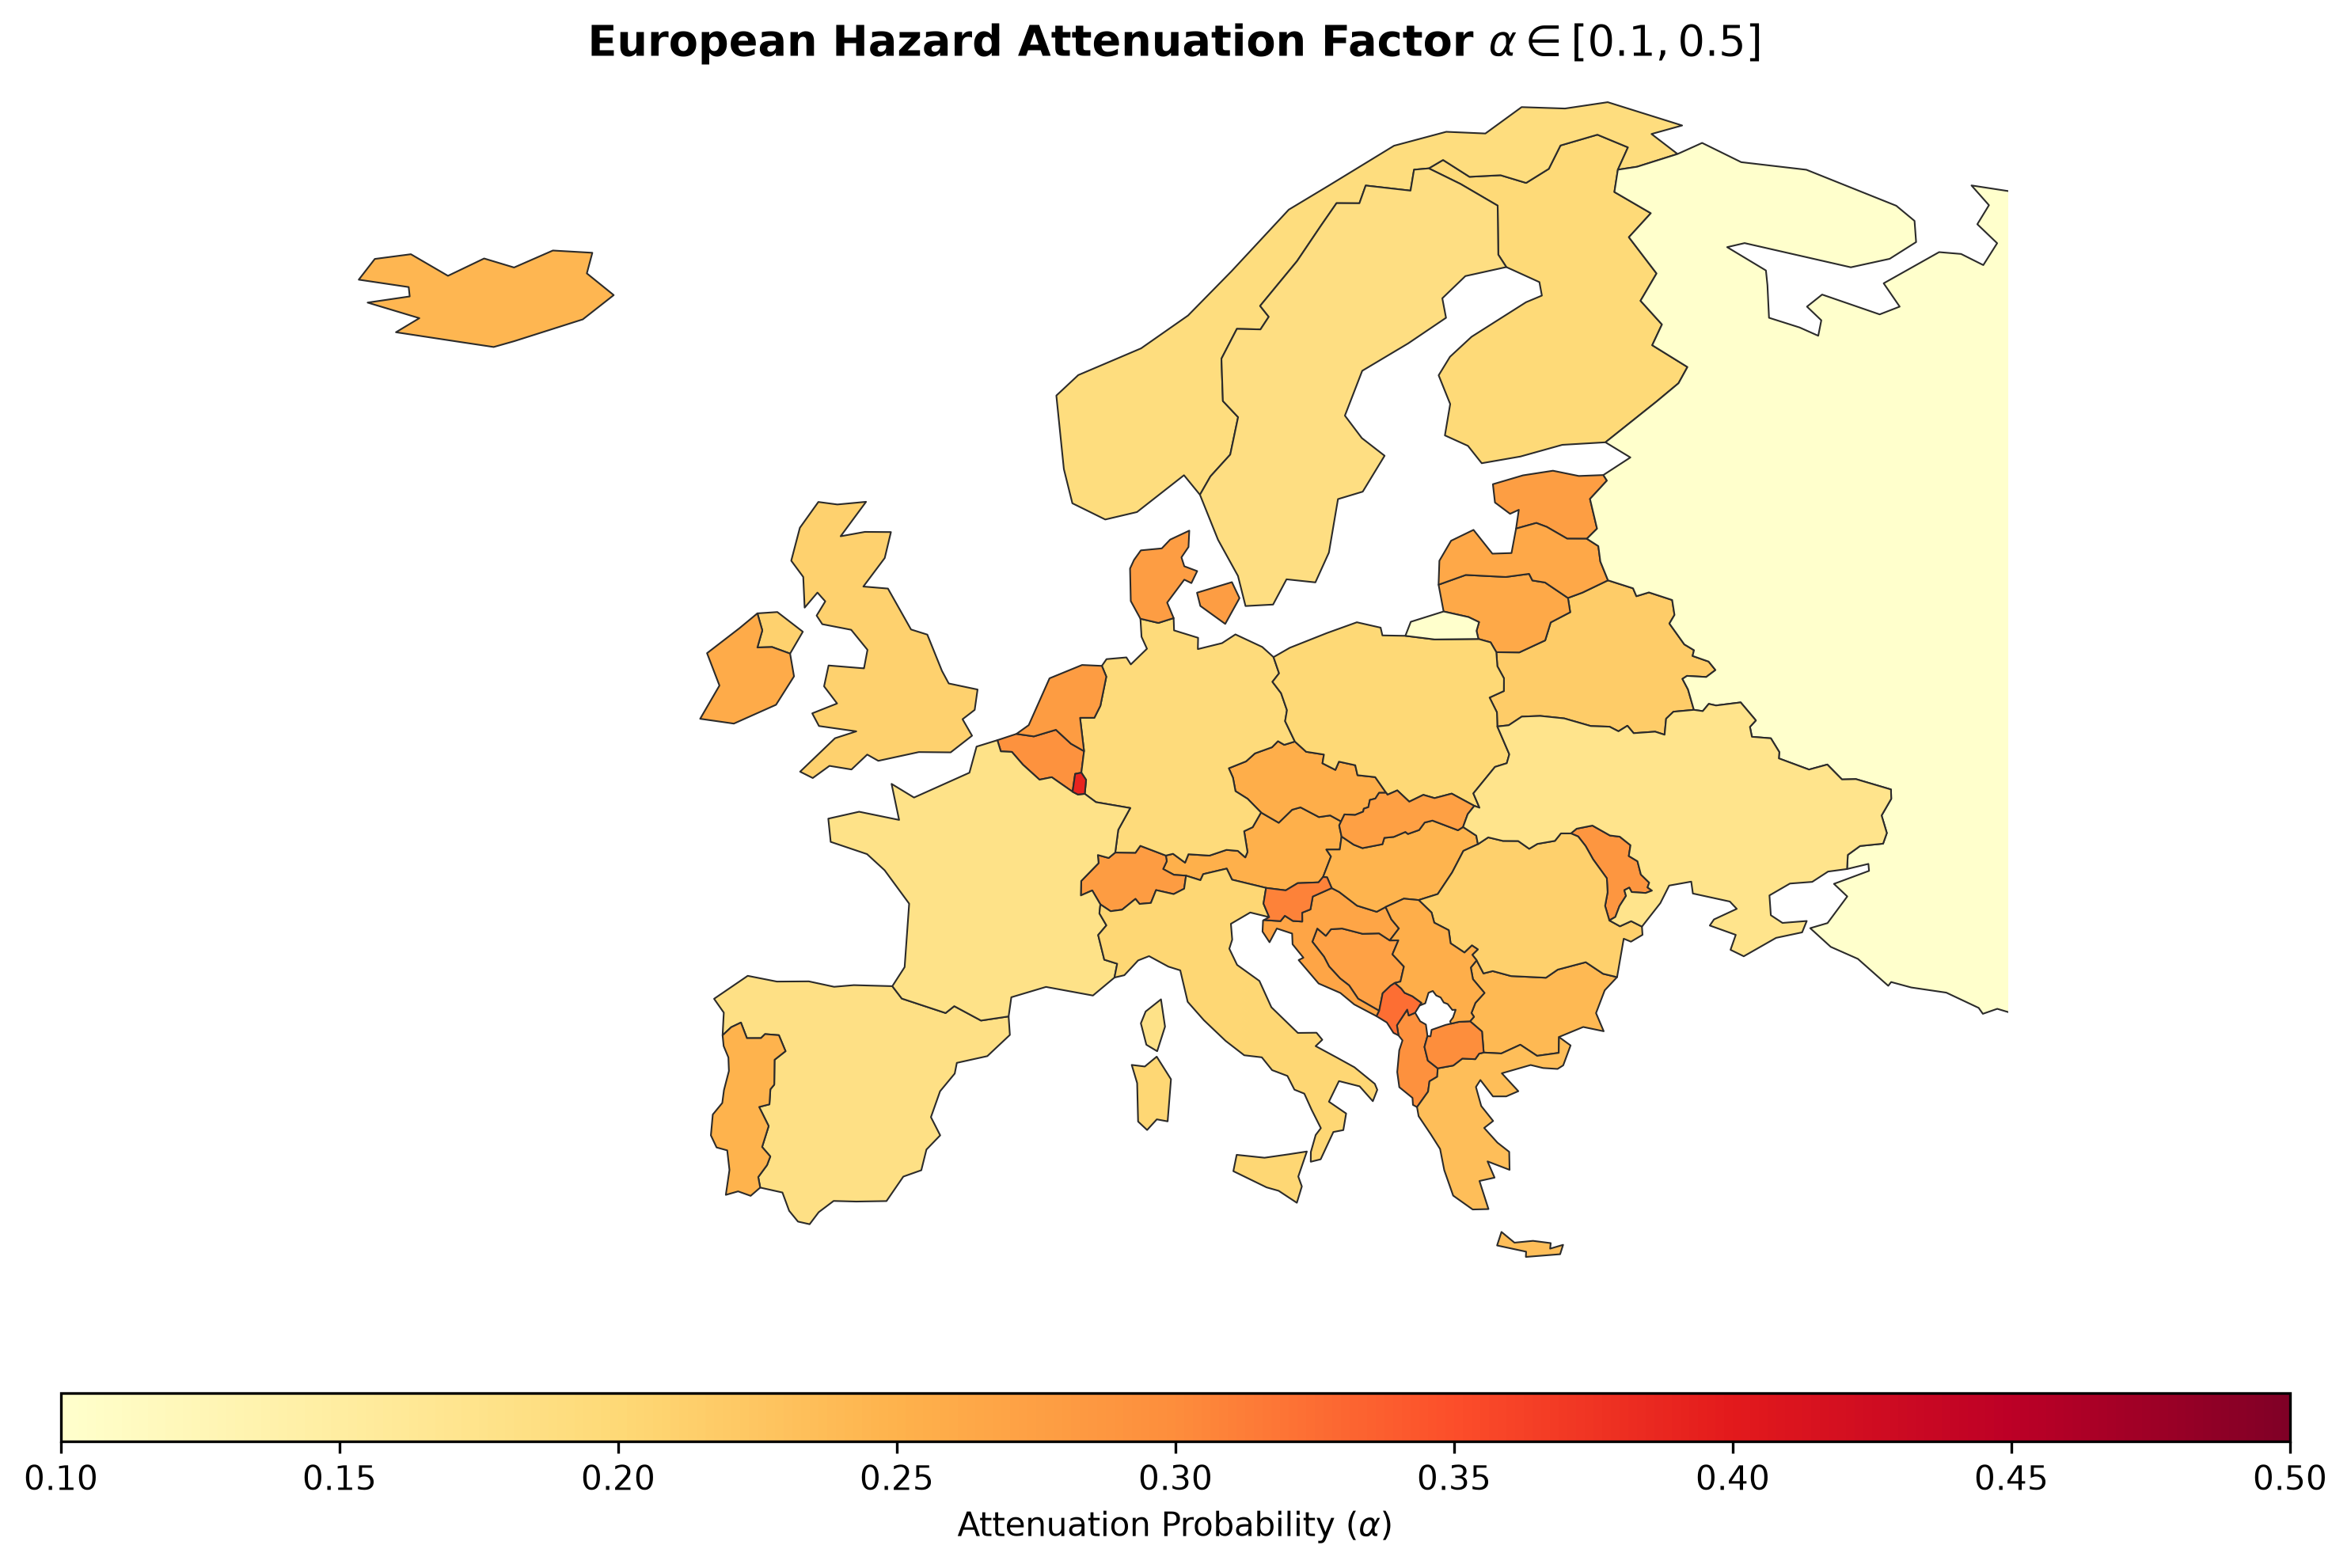

In [76]:
geo_url = "https://raw.githubusercontent.com/python-visualization/folium/master/examples/data/world-countries.json"
world = gpd.read_file(geo_url)

df_map = df_attenuation.copy()
df_map['iso3'] = df_map['Country'].map(ISO3_MAP)

europe_gdf = world.merge(df_map, left_on='id', right_on='iso3', how='inner')

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)

divider = make_axes_locatable(ax)
cax = divider.append_axes("bottom", size="4%", pad=0.45)

europe_gdf.plot(
    column="alpha",
    cmap="YlOrRd",
    vmin=0.10,
    vmax=0.50,
    linewidth=0.5,
    edgecolor="#2b2b2b",
    legend=True,
    cax=cax,
    legend_kwds={
        "orientation": "horizontal",
        "label": r"Attenuation Probability ($\alpha$)"
    },
    ax=ax
)

ax.set_xlim(-25, 45)
ax.set_ylim(34, 72)
ax.set_title(r"European Hazard Attenuation Factor $\alpha \in [0.1, 0.5]$", fontsize=13, weight="bold")
ax.axis("off")

plt.tight_layout()
plt.savefig("../Data/Results/map_attenuation_europe.png", bbox_inches="tight")
plt.show()